# TP2. Extraction d'information

## 1. Keywords

In [6]:
import os
import yake

In [7]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", n=2, top=100)
kw_extractor

In [8]:
# Lister les Fichiers
data_path = "C:\\Users\\lucia\\Traitement-Corpus-Cours\\tac\\data\\txt"
files = [f for f in os.listdir(data_path) if '1906' in f]

In [9]:
# Imprimer le nombre de fichiers identifiés
len(files)

100

In [10]:
for f in sorted(files)[:7936]:
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1906-01-05_01-00001.txt mentions these keywords: qu’il faut, Féral die, faut jamais, n’ai Jamais, dies concours, Sanctions scolaires, die compositions, Edition ABONNEMENT, punitions jamais, vie scolaire, système die, public die, jamais mis, Notre’correspondant die, die Vraninç, lés enfants, dit qu’il, celte vie, die prendre, lés lignes, petite ligne, puis Filippo, suite die, dit Vitalis, cou die, faire seul, acte die...
KB_JB838_1906-01-10_01-00003.txt mentions these keywords: Love Tomsy, Hector Denis, mercredi matin, rue Veydt, bonnes maisons, dernier fut, baron van, maison mortuaire, Adolphe Delhaize, Société royale, Pilules Foster, fut mis, d’une société, officiers fut, Ire qualité...
KB_JB838_1906-01-14_01-00007.txt mentions these keywords: service personnel, service général, bataillons actifs, service actif, service obligatoire, général Renard, Olivier Réral, xfé assidus, iez-xouz permettre, Jacques Renault, régiments actifs, fit Olivier, Olivier d’une, général Brassi, d’

## 2. Nuages de mots

In [11]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\lucia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [12]:
# Stopwords de base
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]

# 1ere itération
sw += ["lors", "toute", "avant", "chez", "faites", "rue", "très", "cabinet", "chambre", "hom", "saint",
       "avenue", "boulevard", "moment", "donc", "alor", "dont", "sourtout", "hommes", "homme", "pays"]

# 2eme itération
sw += ["place", "trop", "dès","jours", "toujours","francs","fois","bon", "bonne", "heures", "belgique",
       "minutes","peu", "salle", "vend", "Belgique", "hier", "centre", "midi", "quand", "quelques", "quelque"]

# 3eme itération
sw += ["grand", "grande", "grands", "grandes", "mois", "ans", "an", "année", "jour", "femme", "femmes",
       "chaussée", "quartier", "village", "commune", "province", "monde", "nord", "suite", "près"]

# 4eme itération
sw += ["monsieur", "madame", "monsieurs", "mesdames","soir", "Le Soir", "prix", "vendre", 
       "maison", "louer", "fille", "fils", "garçon", "etc", "dés", "demande", "état", "occasion"]
sw = set(sw)

In [13]:
# Choisir une année
year = 1906

In [14]:
# Lister les fichiers de cette année
data_path = 'C:\\Users\\lucia\\Traitement-Corpus-Cours\\tac\\data'
txt_path = 'C:\\Users\\lucia\\Traitement-Corpus-Cours\\tac\\data\\txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [15]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [16]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [17]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

'Veadredi 5 JaaYÎer 1906,3! Edition ABONNEMENT pour toute la Belgique : S mois, fr.2.25; 6 mois, tr. 4.25; 4 an, 8 te. --issai*- Le SOER est distribué dans toute l’agglomération bruxelloise (rez-do* ch'

In [18]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = 'C:\\Users\\lucia\\Traitement-Corpus-Cours\\tac\\data\\tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [19]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'Veadredi 5 JaaYÎer 1906,3! Edition ABONNEMENT pour toute la Belgique : S mois, fr.2.25; 6 mois, tr. 4.25; 4 an, 8 te. --issai*- Le SOER est distribué dans toute l’agglomération bruxelloise (rez-do* chaussée) contre 30 centimes par moi*, montant des Irais d’envoL Abonuornect d\'étage : 60 cent, par mois* Hollande et Grand-Duché 4 6 fr. par an. - Pays do l\'Union postale 24 Ir. par a "- On peut s aoùnner à tous les bureetust d§ jjoste étaux facteurs en tournis. . . TIRAGE: 150.000 EXEMPlj No 5 parai'

## Nettoyage du fichier

In [20]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [21]:
clean_text(year, folder=temp_path)

'Output has been written in C:\\Users\\lucia\\Traitement-Corpus-Cours\\tac\\data\\tmp/1906_clean.txt!'

In [22]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'VEADREDI JAAYÎER EDITION ABONNEMENT ISSAI SOER DISTRIBUÉ AGGLOMÉRATION BRUXELLOISE REZ CENTIMES MONTANT IRAIS ENVOL ABONUORNECT ÉTAGE CENT HOLLANDE DUCHÉ UNION POSTALE AOÙNNER BUREETUST JJOSTE ÉTAUX FACTEURS TOURNIS TIRAGE EXEMPLJ PARAISSENT PAGES BUREAUX PLAGE LOUVAIN REDACTION TÉLÉPHONES ADMINISTRATION TÉLÉPHONE ÉDITIONSPAR ÀSTLETB INSERTIONS PETITES ANNONCES LIGNES PETITE LIGNE FAITS CORPS LIGUE FAITS DIVERS RÉPARATIONS JUDICIAIRES LIGNE SPORT CARNET MODE NÉCROLOGIES LIGNE RÉCLAMES SPECTACLES'

### Afficher les termes les plus fréquents


In [23]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('BRUXELLES', 1031), ('ECR', 438), ('CUIS', 372), ('FIL', 357), ('VENTE', 349), ('QUART', 348), ('COUR', 339), ('ADR', 334), ('GAZ', 329), ('EAU', 328)]


### Créer, stocker et afficher le nuage de mots

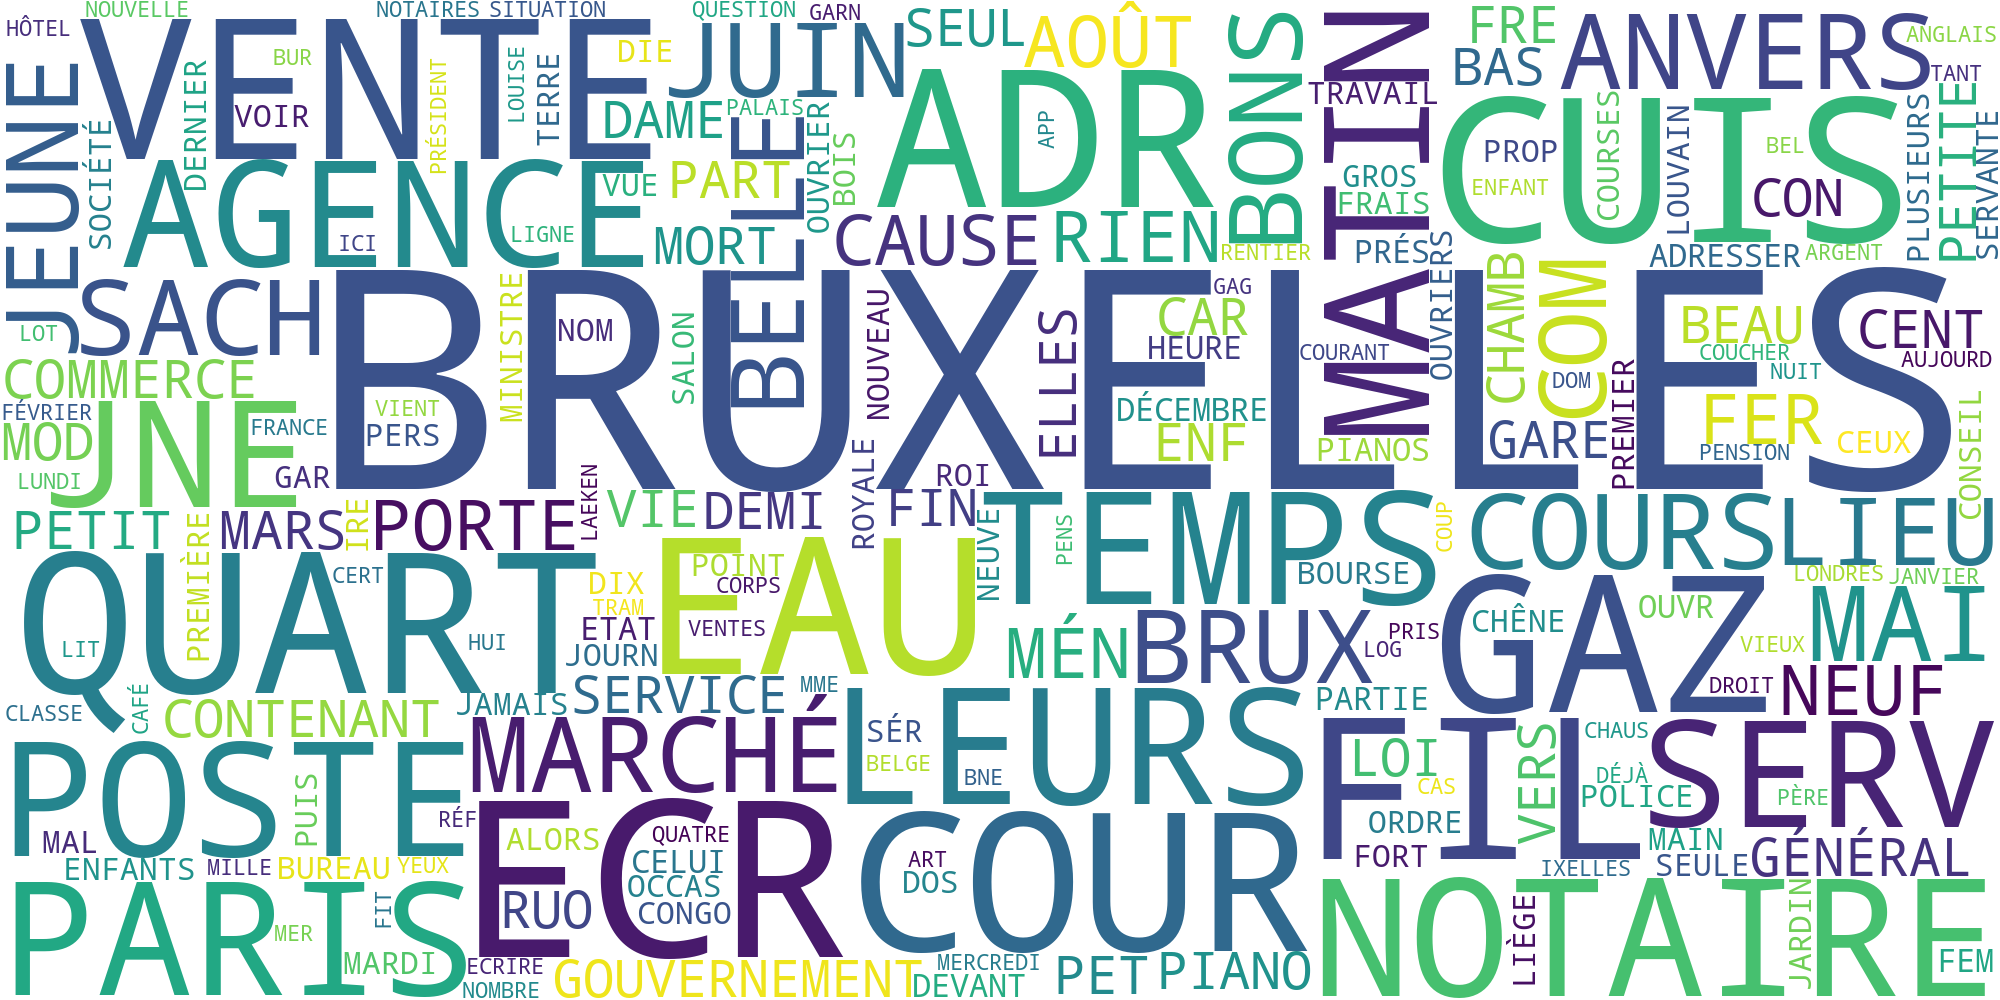

In [24]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

# Reconnaissance d'entités nommées avec SpaCy pour l'année 1906

In [25]:
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

In [26]:
nlp = spacy.load('fr_core_news_md')

In [27]:
# Charger le texte
n=1000000
text = open("C:\\Users\\lucia\\Traitement-Corpus-Cours\\tac\\data\\tmp\\1906.txt", encoding='utf-8').read()[:n]

In [28]:
%%time
# Traiter le texte

doc = nlp(text)

CPU times: total: 1min 32s
Wall time: 1min 35s


Personnes

In [29]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1

In [30]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 57 fois dans le corpus
Ethel apparait 26 fois dans le corpus
jne hom apparait 18 fois dans le corpus
Agence Rossel apparait 16 fois dans le corpus
Ledit apparait 15 fois dans le corpus
culs apparait 12 fois dans le corpus
Calme apparait 11 fois dans le corpus
Louise apparait 11 fois dans le corpus
b. cert apparait 11 fois dans le corpus
Belg apparait 11 fois dans le corpus
Louis XV apparait 10 fois dans le corpus
De Coster apparait 10 fois dans le corpus
Gemma apparait 8 fois dans le corpus
Reine apparait 8 fois dans le corpus
Roum apparait 8 fois dans le corpus
Henri apparait 8 fois dans le corpus
Aristide apparait 8 fois dans le corpus
Féral apparait 7 fois dans le corpus
chamb apparait 7 fois dans le corpus
Température apparait 7 fois dans le corpus
Boum apparait 7 fois dans le corpus
franco apparait 7 fois dans le corpus
Simon apparait 7 fois dans le corpus
Pommeroi apparait 6 fois dans le corpus
Brugmann apparait 6 fois dans le corpus
Créd apparait 6 fois dans le c

Lieux

In [31]:
# Compter les entités
loc = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "LOC" and len(ent.text) > 3:
        loc[ent.text] += 1

In [32]:
# Trier et imprimer

sorted_loc = sorted(loc.items(), key=lambda kv: kv[1], reverse=True)

for location, freq in sorted_loc[:50]:
    print(f"{location} apparait {freq} fois dans le corpus")

Bruxelles apparait 211 fois dans le corpus
Anvers apparait 60 fois dans le corpus
Paris apparait 60 fois dans le corpus
Nord apparait 49 fois dans le corpus
Laeken apparait 41 fois dans le corpus
Liège apparait 35 fois dans le corpus
Centre apparait 31 fois dans le corpus
Brésil apparait 30 fois dans le corpus
Ixelles apparait 30 fois dans le corpus
Brux apparait 27 fois dans le corpus
Bourse apparait 26 fois dans le corpus
Belgique apparait 25 fois dans le corpus
Londres apparait 25 fois dans le corpus
Etat apparait 23 fois dans le corpus
Schaerbeek apparait 22 fois dans le corpus
Louvain apparait 19 fois dans le corpus
Midi apparait 19 fois dans le corpus
Congo apparait 18 fois dans le corpus
Namur apparait 17 fois dans le corpus
Allemagne apparait 16 fois dans le corpus
Russie apparait 15 fois dans le corpus
Charleroi apparait 15 fois dans le corpus
prop apparait 15 fois dans le corpus
Saint-Pétersbourg apparait 15 fois dans le corpus
Rupel apparait 15 fois dans le corpus
Anderlecht

Organizations

In [33]:
# Compter les entités
org = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "ORG" and len(ent.text) > 3:
        org[ent.text] += 1

In [34]:
# Trier et imprimer

sorted_org = sorted(org.items(), key=lambda kv: kv[1], reverse=True)

for organization, freq in sorted_org[:50]:
    print(f"{organization} apparait {freq} fois dans le corpus")

Chambre apparait 14 fois dans le corpus
Minnie apparait 12 fois dans le corpus
Parlement apparait 9 fois dans le corpus
Espag apparait 9 fois dans le corpus
Société apparait 8 fois dans le corpus
An dem apparait 7 fois dans le corpus
OBLIQAT apparait 6 fois dans le corpus
O n dem apparait 5 fois dans le corpus
COIFFEUR apparait 5 fois dans le corpus
Conseil apparait 5 fois dans le corpus
trav apparait 4 fois dans le corpus
Tokio apparait 4 fois dans le corpus
OBLICAT apparait 4 fois dans le corpus
PIANOS apparait 4 fois dans le corpus
Société anonyme apparait 4 fois dans le corpus
COIFFEUR dem apparait 4 fois dans le corpus
Revue Maritime apparait 4 fois dans le corpus
Sûreté apparait 4 fois dans le corpus
Société protectrice des animaux apparait 3 fois dans le corpus
bne ouvrière apparait 3 fois dans le corpus
r. Royale apparait 3 fois dans le corpus
G n dem apparait 3 fois dans le corpus
Railways Electricité apparait 3 fois dans le corpus
Galeries apparait 3 fois dans le corpus
CHEM 

# 4. Analyse de sentiments

In [35]:
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

In [36]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

In [37]:
# phrase1
get_sentiment("M. Jules De Le Court, premier président de la Cour d’appel, est mort ce matin.")

This text is 20% positive and 15% subjective.


In [38]:
#phrase2
get_sentiment("La vue de son fils fut pour la malade une source de douleurs nouvelles.")

This text is 12% negative and 32% subjective.


In [39]:
#phrase3
get_sentiment("Les quatre balles ont atteint le comte au bras et dans d’autres parties du corps.")

This text is 10% negative and perfectly objective.


In [40]:
#phrase4
get_sentiment("La vérité c’est que le ministre des finances n’a fait quant à présent qu’étudier les grandes lignes d’un nouveau projet.")

This text is 25% positive and 20% subjective.


In [41]:
#phrase5
get_sentiment("La loi sur la séparation des Eglises et de l’Etat sera appliquée dans un esprit libéral, sans persécution, mais avec fermeté.")

This text is 8% positive and 18% subjective.


In [42]:
#phrase6
get_sentiment("Par le fait de cette intervention, l’élection du candidat démocrate constituerait, un échec personnel pour le Président.")

This text is 5% positive and 10% subjective.


In [43]:
#phrase7
get_sentiment("Ce champion infatigable des droits de la femme était encore sur la brèche à l’âge de quatra-vingt-six ans, et c’est ansi qu’elle a contracté la pneumonie qui l’a emportée.")

This text is 2% negative and perfectly objective.


In [44]:
#phrase8
get_sentiment("La ville de Tétouan désire vivement la constitution du corps de police européen.")

This text is neutral and perfectly objective.


In [45]:
#phrase9
get_sentiment("Le Pape a dit très nettement qu’il ne voulait ni sédition, ni violences.")

This text is 1% positive and 65% subjective.


In [46]:
#phrase10
get_sentiment("Le Roi, qui portait l’uniforme du régiment de Pavie, a’inspecté les préparatifs et s’est entretenu avec les fonctionnaires et les généraux.")

This text is neutral and perfectly objective.
